# 线性回归的梯度下降

线性回归模型   
$$f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{1}$$
代价函数 
$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2\tag{2}$$

In [11]:
import numpy as np
import matplotlib as plt

x_train=np.array([1.0,2.0])
y_train=np.array([300.0,500.0])

# 代价函数
# 模型 y= wx+b
# 代价函数 J= sum((wx+b)-y)²  累加i-m的所有误差平方
def cost_func(x,y,w,b):
    m=x.shape[0]
    total_cost=0
    for i in range(m):
        f_wb=w*x[i]+b
        cost=(f_wb-y[i])**2
        total_cost+=cost
    # 使用1/(2*m) 保留和算法定义一样的语义
    # 同时便于
    return 1/(2*m)*total_cost



分别对w、b求偏导，同时需要注意更新参数时需要同步更新所有参数，避免计算后续参数的梯度时受到影响。(计算b的参数时如果提前更新了w参数会导致参数错误)  
$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline
\;  w &= w -  \alpha \frac{\partial J(w,b)}{\partial w} \tag{3}  \; \newline
 b &= b -  \alpha \frac{\partial J(w,b)}{\partial b}  \newline \rbrace
\end{align*}$$

$$
\begin{align}
\frac{\partial J(w,b)}{\partial w}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)} \tag{4}\\
  \frac{\partial J(w,b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)}) \tag{5}\\
\end{align}
$$

In [46]:
# 梯度计算函数 - 
# 纯计算梯度值
# 后续在梯度下降算法中使用
def gradient_func(x,y,w,b):
    m = x.shape[0]

    total_dw = 0
    total_db = 0
    for i in range(m):
        fwb = w*x[i]+b
        dj_dw_i = (fwb-y[i])*x[i]
        dj_db_i = fwb-y[i]
        total_dw += dj_dw_i
        total_db += dj_db_i

    result_dw = 1/m * total_dw
    result_db = 1/m * total_db
    return result_dw,result_db
        
    

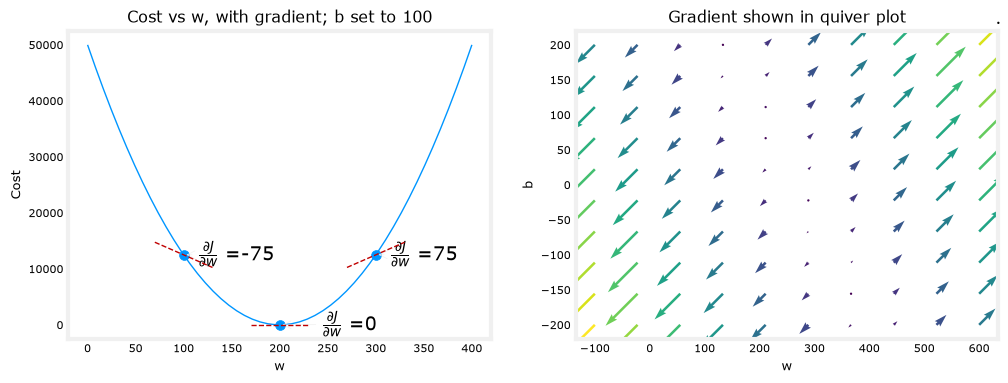

In [14]:
# 这里借用一下课程中绘制代价函数关于其中一个参数w的一些偏导数。
import math, copy
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')
from lab_utils_uni import plt_house_x, plt_contour_wgrad, plt_divergence, plt_gradients

plt_gradients(x_train, y_train, cost_func, gradient_func)
plt.show()

In [41]:
# 定义梯度下降算法
# 从初始参数出发，反复调用梯度计算方法从而更新参数直到收敛或者到达迭代次数

# alpha: 学习率
# num_iters: 迭代次数
# cost_func: 代价函数
# gredient_func: 梯度计算函数
def gradient_decent(x,y,w,b,alpha,num_iters,cost_func,gradient_func):
    result_w=w
    result_b=b
    for i in range(num_iters):
        dj_w,dj_b=gradient_func(x,y,result_w,result_b)
        result_w -= alpha * dj_w
        result_b -= alpha * dj_b

    return result_w,result_b

In [52]:
# 训练
x_train=np.array([1.0,2.0])
y_train=np.array([300.0,500.0])
# alpha=0.1
alpha=1.0e-2
num_iters=100000
w=0
b=0

w,b=gradient_decent(x_train,y_train,w,b,alpha,num_iters,cost_func,gradient_func)

print(w,b)

# 预测
# x=1
# predict=w*x+b
# print(predict)

print(w*1.0+b)
print(w*1.2+b)
print(w*2.0+b)


199.99999999999005 100.00000000001563
300.0000000000057
340.0000000000037
499.99999999999574


1000


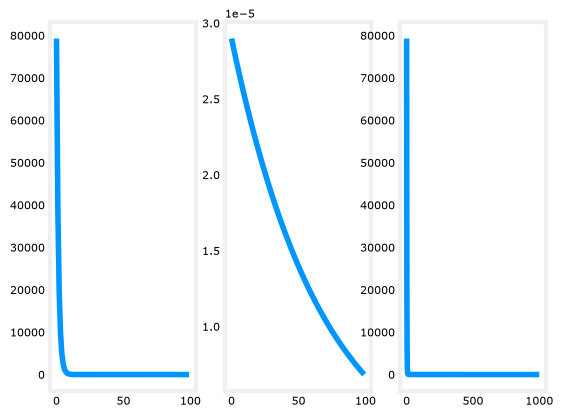

In [72]:
# 上文完成了梯度下降的基本逻辑
# 为了便于观察，可以在算法中抽样记录训练过程中的参数，用于观察训练的状态
# 通过记录参数和代价可以分析训练是否已经收敛
# 如果曲线趋于平稳,则说明模型以及收敛
# 如果曲线仍然在下降,说明需要增加迭代次数
# 如果曲线震荡或者上升,说明学习率太大
def gradient_decent(x,y,w,b,alpha,num_iters,cost_func,gradient_func):
    result_w=w
    result_b=b
    history_j=[]
    history_p=[]
    for i in range(num_iters):
        dj_w,dj_b=gradient_func(x,y,result_w,result_b)
        result_w -= alpha * dj_w
        result_b -= alpha * dj_b

        if(i%10==0):
            cost=cost_func(x,y,result_w,result_b)
            history_j.append(cost)

    return result_w,result_b,history_j


x_train=np.array([1.0,2.0])
y_train=np.array([300.0,500.0])
# alpha=0.1
alpha=1.0e-2
num_iters=10000
w=0
b=0

w,b,history_j=gradient_decent(x_train,y_train,w,b,alpha,num_iters,cost_func,gradient_func)

# 迭代过程中抽样的代价
print(len(history_j))
plt.subplot(1,3,1)
plt.plot(history_j[:100])
plt.subplot(1,3,2)
plt.plot(history_j[900:])
plt.subplot(1,3,3)
plt.plot(history_j)
